# StreamView Analytics — EDA para Gerencia de Marketing

**Proyecto:** Caso Semestral StreamView Analytics — Visual Analytics 2026  
**Stakeholder seleccionado:** Gerencia de Marketing

## 0. Configuración y rutas reproducibles

El código busca los CSV tanto en la carpeta actual como en `data/` y `../data/`. Así puede ejecutarse en Google Colab, Jupyter local o dentro de la estructura profesional del proyecto sin rutas absolutas.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Paleta accesible y consistente: rojo = películas, azul = series
ROJO = '#E50914'
AZUL = '#1769E0'
VERDE = '#16805C'
AMBAR = '#D48500'
GRIS = '#6B7280'
OSCURO = '#111827'
GRIS_CLARO = '#F3F4F6'

plt.rcParams.update({
    'figure.figsize': (11, 6),
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'axes.titlesize': 14,
    'axes.titlelocation': 'left',
    'font.size': 10,
})



# Rutas del proyecto (funciona ejecutando desde la raíz o desde notebooks/)
BASE = Path('.') if Path('data').exists() else Path('..')
RAW_DIR = BASE / 'data' / 'raw'

# Cargar los datos
df_movies = pd.read_csv(RAW_DIR / 'Netflix_Movies_Detailed_up_to_2025.csv')
df_tv_shows = pd.read_csv(RAW_DIR / 'Netflix_TV_Shows_Detailed_up_to_2025.csv')

OUT_DIR = BASE / 'images' / 'marketing'
OUT_DIR.mkdir(parents=True, exist_ok=True)


def guardar(fig, nombre):
    ruta = OUT_DIR / f'{nombre}.png'
    fig.savefig(ruta, dpi=160, bbox_inches='tight', facecolor='white')
    print(f'Figura guardada: {ruta}')


def nota_fuente(fig, texto):
    fig.text(0.01, -0.03, texto, fontsize=8.5, color=GRIS)

print('Movies:', df_movies)
print('TV Shows:', df_tv_shows)
print('Carpeta de figuras:', OUT_DIR)

Movies:        show_id   type                                         title                               director                                               cast  \
0        10192  Movie                           Shrek Forever After                          Mike Mitchell  Mike Myers, Eddie Murphy, Cameron Diaz, Antoni...   
1        27205  Movie                                     Inception                      Christopher Nolan  Leonardo DiCaprio, Joseph Gordon-Levitt, Ken W...   
2        12444  Movie  Harry Potter and the Deathly Hallows: Part 1                            David Yates  Daniel Radcliffe, Emma Watson, Rupert Grint, T...   
3        38757  Movie                                       Tangled             Byron Howard, Nathan Greno  Mandy Moore, Zachary Levi, Donna Murphy, Ron P...   
4        10191  Movie                      How to Train Your Dragon            Chris Sanders, Dean DeBlois  Jay Baruchel, Gerard Butler, Craig Ferguson, A...   
...        ...    ...     

## 1. Carga y consolidación

Se integran películas y series en un catálogo único. Las variables comparables se analizan conjuntamente; los atributos exclusivos de películas no se usan en el análisis de Marketing.

In [3]:
movies = df_movies
shows = df_tv_shows

catalogo_raw = pd.concat([movies, shows], ignore_index=True, sort=False)
print(f'Películas: {len(movies):,}')
print(f'Series: {len(shows):,}')
print(f'Catálogo antes de deduplicar: {len(catalogo_raw):,}')

catalogo_raw.head(3)

Películas: 16,000
Series: 16,000
Catálogo antes de deduplicar: 32,000


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,language,description,popularity,vote_count,vote_average,budget,revenue
0,10192,Movie,Shrek Forever After,Mike Mitchell,"Mike Myers, Eddie Murphy, Cameron Diaz, Antoni...",United States of America,2010-05-16,2010,6.38,NaN,"Comedy, Adventure, Fantasy, Animation, Family",en,A bored and domesticated Shrek pacts with deal...,203.89,7449,6.38,"165,000,000.00","752,600,867.00"
1,27205,Movie,Inception,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ken W...","United Kingdom, United States of America",2010-07-15,2010,8.37,NaN,"Action, Science Fiction, Adventure",en,"Cobb, a skilled thief who commits corporate es...",156.24,37119,8.37,"160,000,000.00","839,030,630.00"
2,12444,Movie,Harry Potter and the Deathly Hallows: Part 1,David Yates,"Daniel Radcliffe, Emma Watson, Rupert Grint, T...","United Kingdom, United States of America",2010-11-17,2010,7.74,NaN,"Adventure, Fantasy",en,"Harry, Ron and Hermione walk away from their l...",121.19,19327,7.74,"250,000,000.00","954,305,868.00"


## 2. Auditoría de calidad relevante para Marketing

Antes de definir campañas se revisa si las variables utilizadas son interpretables. Esta sección evita recomendaciones basadas en campos inválidos, incompletos o con significado distinto al documentado.

In [4]:
duplicados = catalogo_raw['show_id'].duplicated().sum()
coincidencia_rating = (movies['rating'] == movies['vote_average']).mean()

calidad = pd.DataFrame({
    'Hallazgo': [
        'Registros duplicados por show_id',
        'rating coincide con vote_average en películas',
        'duration nula en películas',
        'duration constante en series',
        'Contenidos con vote_average = 0',
        'Nulos de genres en catálogo',
        'Nulos de country en catálogo',
        'Nulos de director en series',
    ],
    'Resultado': [
        f'{duplicados:,}',
        f'{coincidencia_rating:.1%}',
        f'{movies.duration.isna().mean():.1%}',
        f'{(shows.duration == "1 Seasons").mean():.1%}',
        f'{(catalogo_raw.vote_average == 0).sum():,}',
        f'{catalogo_raw.genres.isna().sum():,}',
        f'{catalogo_raw.country.isna().sum():,}',
        f'{shows.director.isna().sum():,} ({shows.director.isna().mean():.1%})',
    ],
    'Decisión de Marketing': [
        'Deduplicar por show_id antes de crear KPIs o rankings.',
        'No usar rating como clasificación etaria: es redundante con la valoración.',
        'Excluir duración del análisis; no aporta segmentación válida.',
        'Excluir duración del análisis; todos los registros indican 1 temporada.',
        'Excluir de promedios/rankings de valoración; se conserva para conteo de catálogo.',
        'Excluir solo de análisis por género; mantener en otros KPIs.',
        'Excluir solo de análisis por país; mantener en otros KPIs.',
        'No usar dirección como criterio central para campañas de series.',
    ]
})
calidad

,Hallazgo,Resultado,Decisión de Marketing
0,Registros duplicados por show_id,406,Deduplicar por show_id antes de crear KPIs o r...
1,rating coincide con vote_average en películas,100.0%,No usar rating como clasificación etaria: es r...
2,duration nula en películas,100.0%,Excluir duración del análisis; no aporta segme...
3,duration constante en series,100.0%,Excluir duración del análisis; todos los regis...
4,Contenidos con vote_average = 0,"4,572",Excluir de promedios/rankings de valoración; s...
5,Nulos de genres en catálogo,"1,081",Excluir solo de análisis por género; mantener ...
6,Nulos de country en catálogo,"2,263",Excluir solo de análisis por país; mantener en...
7,Nulos de director en series,"10,965 (68.5%)",No usar dirección como criterio central para c...


### Decisiones de limpieza

- Se elimina la duplicación por `show_id`, conservando el primer registro.
- Se convierte `date_added` a fecha y se deriva `year_added`, el indicador temporal correcto para el crecimiento de catálogo.
- Se excluyen `rating` y `duration` de las vistas analíticas por ser redundante/no informativa.
- Se mantienen `popularity`, `vote_average` y `vote_count`, pero se evita asumir que cualquiera de ellas representa por sí sola el éxito de una campaña.
- Los títulos se priorizan mediante un score transparente y editable; **no es un modelo predictivo**.

In [5]:
# Catálogo limpio, deduplicado por tipo y show_id
catalogo = catalogo_raw.drop_duplicates(subset=['type', 'show_id'], keep='first').copy()

# Conversión a fecha y extracción de año como entero (evita que los años se vean como 2020.0 si hay nulos)
catalogo['date_added'] = pd.to_datetime(catalogo['date_added'], errors='coerce')
catalogo['year_added'] = catalogo['date_added'].dt.year.astype('Int64')

catalogo['tipo_es'] = catalogo['type'].map({'Movie': 'Película', 'TV Show': 'Serie'})
catalogo['titulo_corto'] = catalogo['title'].str.strip()

# Idiomas principales mapeados para una lectura ejecutiva; los restantes conservan su código.
MAPA_IDIOMAS = {
    'en':'Inglés', 'zh':'Chino', 'ja':'Japonés', 'ko':'Coreano', 'fr':'Francés',
    'es':'Español', 'de':'Alemán', 'hi':'Hindi', 'tl':'Filipino', 'pt':'Portugués',
    'it':'Italiano', 'ru':'Ruso', 'ar':'Árabe', 'th':'Tailandés', 'tr':'Turco',
    'id':'Indonesio', 'nl':'Neerlandés', 'pl':'Polaco', 'sv':'Sueco', 'da':'Danés',
    'fi':'Finés', 'no':'Noruego', 'he':'Hebreo', 'el':'Griego', 'uk':'Ucraniano',
    'ro':'Rumano', 'hu':'Húngaro', 'cs':'Checo', 'xx':'Desconocido'
}

# Uso de .replace() es más limpio que .map().fillna()
catalogo['idioma'] = catalogo['language'].replace(MAPA_IDIOMAS)

# Base apta para evaluar valoración; popularity se conserva como índice relativo.
base_marketing = catalogo[(catalogo['vote_average'] > 0) & (catalogo['vote_count'] >= 1)].copy()

print(f'Catálogo único: {len(catalogo):,} contenidos')
print(f'Base con valoración válida: {len(base_marketing):,} contenidos')
print(f'Rango de incorporación: {catalogo.year_added.min()}–{catalogo.year_added.max()}')

Catálogo único: 31,991 contenidos
Base con valoración válida: 27,414 contenidos
Rango de incorporación: 2010–2025


## 3. Construcción de vistas de Marketing

`genres` y `country` contienen varios valores por título. Se crean tablas normalizadas para contar correctamente relaciones por género y por país. También se genera una taxonomía de **familias de género** para evitar interpretar como equivalentes categorías que aparecen separadas en la fuente, por ejemplo `Action` y `Action & Adventure`. La fuente original se conserva sin cambios.

In [6]:
def explotar_multivalor(df, columna, nueva_columna):
    salida = df.dropna(subset=[columna]).copy()
    salida[nueva_columna] = salida[columna].str.split(r',\s*')
    salida = salida.explode(nueva_columna)
    salida[nueva_columna] = salida[nueva_columna].str.strip()
    return salida

por_genero = explotar_multivalor(base_marketing, 'genres', 'genero')
por_pais = explotar_multivalor(base_marketing, 'country', 'pais')

# Agrupación analítica para evitar fragmentación de categorías similares.
FAMILIA_GENERO = {
    'Action':'Acción y aventura', 'Adventure':'Acción y aventura', 'Action & Adventure':'Acción y aventura',
    'Science Fiction':'Ciencia ficción y fantasía', 'Fantasy':'Ciencia ficción y fantasía', 'Sci-Fi & Fantasy':'Ciencia ficción y fantasía',
    'Comedy':'Comedia', 'Drama':'Drama', 'Animation':'Animación', 'Thriller':'Suspenso y misterio',
    'Mystery':'Suspenso y misterio', 'Crime':'Crimen', 'Horror':'Terror', 'Romance':'Romance',
    'Family':'Familiar', 'Documentary':'Documental', 'Reality':'Reality', 'War & Politics':'Guerra y política',
    'Talk':'Conversación', 'News':'Noticias', 'Western':'Western', 'History':'Historia', 'Music':'Música',
    'TV Movie':'Película TV'
}

# Aplicando .replace() para simplificar
por_genero['familia_genero'] = por_genero['genero'].replace(FAMILIA_GENERO)

print(f'Relaciones contenido-género: {len(por_genero):,}')
print(f'Géneros originales: {por_genero.genero.nunique()}')
print(f'Familias analíticas: {por_genero.familia_genero.nunique()}')
print(f'Relaciones contenido-país: {len(por_pais):,}')

Relaciones contenido-género: 59,800
Géneros originales: 28
Familias analíticas: 23
Relaciones contenido-país: 33,895


## 4. KPIs para Marketing

Los indicadores priorizan alcance potencial, calidad percibida y respaldo de audiencia. Debido a la asimetría extrema de `popularity`, se reporta su **mediana** además del promedio. La calificación se calcula solo sobre títulos con `vote_average > 0`.

In [7]:
kpis_marketing = pd.DataFrame({
    'KPI': [
        'Contenidos únicos', 'Películas', 'Series', 'Popularidad mediana',
        'Popularidad promedio', 'Calificación promedio (0–10)',
        'Contenidos con valoración válida', 'Idiomas principales',
        'Países representados', 'Familias de género'
    ],
    'Valor': [
        len(catalogo),
        (catalogo['type'] == 'Movie').sum(),
        (catalogo['type'] == 'TV Show').sum(),
        catalogo['popularity'].median(),
        catalogo['popularity'].mean(),
        base_marketing['vote_average'].mean(),
        len(base_marketing),
        catalogo['idioma'].nunique(),
        por_pais['pais'].nunique(),
        por_genero['familia_genero'].nunique()
    ]
})
kpis_marketing

,KPI,Valor
0,Contenidos únicos,"31,991.00"
1,Películas,"16,000.00"
2,Series,"15,991.00"
3,Popularidad mediana,22.07
4,Popularidad promedio,42.63
5,Calificación promedio (0–10),6.63
6,Contenidos con valoración válida,"27,414.00"
7,Idiomas principales,83.00
8,Países representados,146.00
9,Familias de género,23.00


## 5. Score de prioridad promocional

Para orientar la conversación de Marketing se construye un score **descriptivo**, no predictivo. Cada componente se normaliza mediante percentiles entre 0 y 1:

\[
	ext{Score de campaña} = 0.45\cdot P(	ext{popularidad}) + 0.30\cdot P(	ext{valoración}) + 0.25\cdot P(\log(1+	ext{votos}))
\]

- **Popularidad (45%)**: señal principal de visibilidad/alcance potencial.
- **Valoración (30%)**: protege la reputación de la campaña.
- **Votos (25%)**: representa respaldo de audiencia y reduce el efecto de títulos con pocas evaluaciones.

Los pesos son una propuesta de negocio explícita y deben ser revisados por Marketing. El score no demuestra causalidad ni estima conversiones.

In [8]:
# Componentes por percentil: robustos ante escalas distintas.
base_marketing['p_popularidad'] = base_marketing['popularity'].rank(pct=True)
base_marketing['p_valoracion'] = base_marketing['vote_average'].rank(pct=True)
base_marketing['p_votos'] = np.log1p(base_marketing['vote_count']).rank(pct=True)
base_marketing['score_campania'] = (
    0.45 * base_marketing['p_popularidad'] +
    0.30 * base_marketing['p_valoracion'] +
    0.25 * base_marketing['p_votos']
)

# Umbrales para cuadrantes: mediana de cada señal en la base apta.
umbral_pop = base_marketing['popularity'].median()
umbral_val = base_marketing['vote_average'].median()

condiciones = [
    (base_marketing.popularity >= umbral_pop) & (base_marketing.vote_average >= umbral_val),
    (base_marketing.popularity >= umbral_pop) & (base_marketing.vote_average < umbral_val),
    (base_marketing.popularity < umbral_pop) & (base_marketing.vote_average >= umbral_val),
]
opciones = [
    'Promocionar: alto alcance y alta valoración',
    'Awareness: alto alcance; validar mensaje y segmentación',
    'Descubrir: alta valoración; aumentar visibilidad',
]
base_marketing['cuadrante_campania'] = np.select(condiciones, opciones, default='No priorizar: bajo alcance y valoración')

base_marketing['cuadrante_campania'].value_counts().rename_axis('Cuadrante').reset_index(name='Contenidos')

,Cuadrante,Contenidos
0,Promocionar: alto alcance y alta valoración,8966
1,No priorizar: bajo alcance y valoración,8433
2,Descubrir: alta valoración; aumentar visibilidad,5273
3,Awareness: alto alcance; validar mensaje y seg...,4742


## 6. Visualizaciones y hallazgos para Marketing

Cada gráfico responde una pregunta operativa y utiliza una codificación elegida por su precisión perceptual. Las fuentes y alcances se incluyen en la propia figura para permitir su reutilización directa en el informe.

### 6.1 ¿Qué categorías concentran el catálogo promocionable?

**Gráfico:** barras horizontales ordenadas.  
**Razón:** permite comparar con precisión la cantidad de títulos entre categorías con etiquetas extensas. La taxonomía se agrupa en familias para reducir la fragmentación de la fuente.

Figura guardada: ..\images\marketing\01_familias_genero_marketing.png


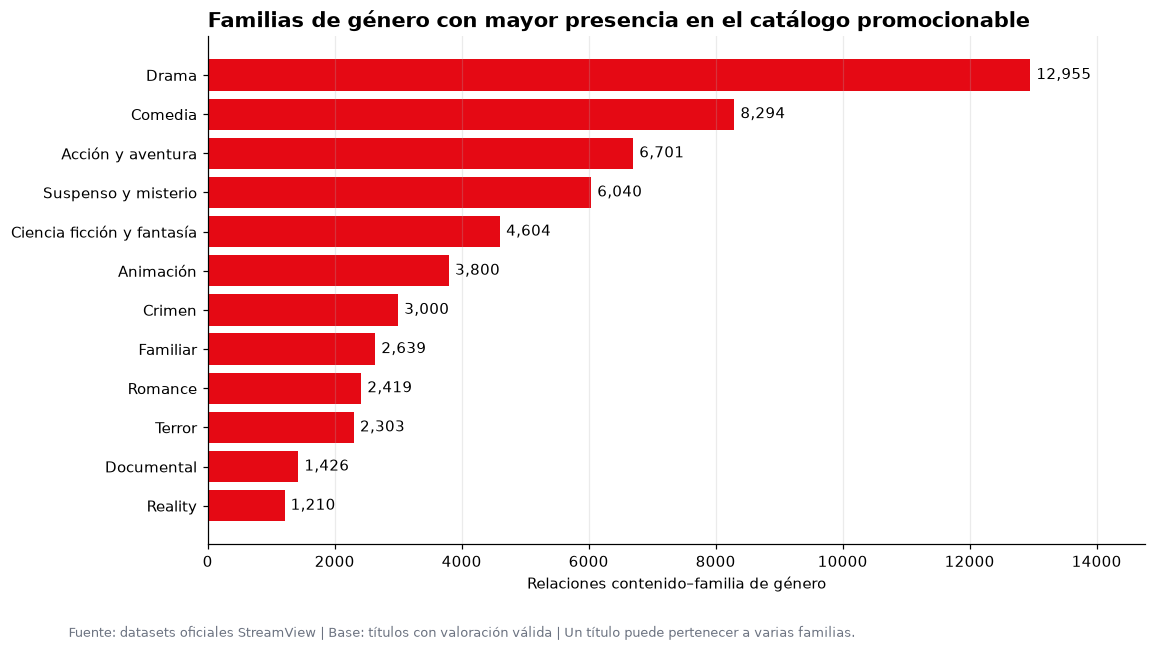

In [9]:
top_familias = por_genero['familia_genero'].value_counts().head(12).sort_values()
fig, ax = plt.subplots(figsize=(11, 6))
barras = ax.barh(top_familias.index, top_familias.values, color=ROJO)
ax.bar_label(barras, fmt='{:,.0f}', padding=4)
ax.set_title('Familias de género con mayor presencia en el catálogo promocionable')
ax.set_xlabel('Relaciones contenido–familia de género')
ax.set_xlim(0, top_familias.max() * 1.14)
ax.grid(axis='x', alpha=.25)
nota_fuente(fig, 'Fuente: datasets oficiales StreamView | Base: títulos con valoración válida | Un título puede pertenecer a varias familias.')
guardar(fig, '01_familias_genero_marketing')
plt.show()

### 6.2 ¿Qué familias combinan alcance potencial y calidad?

**Gráfico:** dispersión.  
**Razón:** compara dos métricas cuantitativas agregadas simultáneamente: popularidad mediana y calificación media. El tamaño expresa cuántas relaciones contiene la familia; no se usa color para una tercera variable, evitando una leyenda innecesaria.

Figura guardada: ..\images\marketing\02_potencial_familias.png


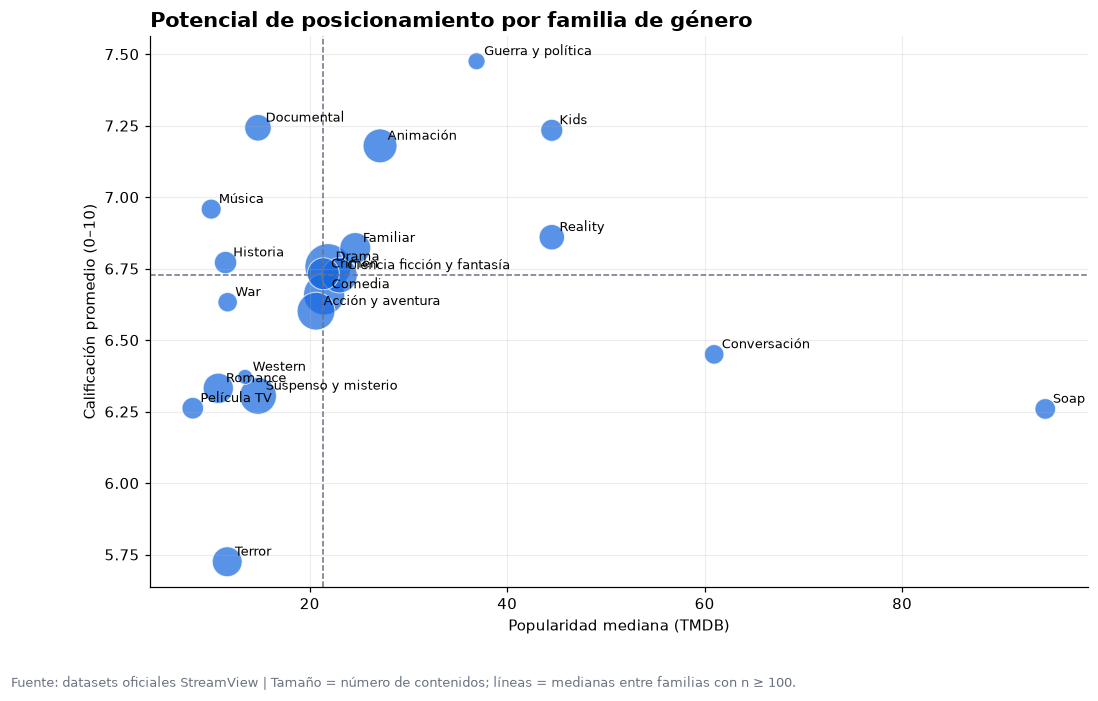

,contenidos,popularidad_mediana,calificacion_promedio,votos_medianos
familia_genero,,,,
Soap,523,94.50,6.26,5.00
Conversación,423,60.96,6.45,3.00
Reality,1209,44.52,6.86,4.00
Kids,678,44.52,7.23,7.00
Guerra y política,244,36.90,7.48,18.00
Animación,3794,27.12,7.18,57.00
Familiar,2635,24.61,6.82,62.00
Ciencia ficción y fantasía,4430,23.03,6.73,142.00
Drama,12885,21.84,6.76,75.00


In [10]:
rendimiento_familias = (por_genero.groupby('familia_genero')
    .agg(contenidos=('show_id','nunique'),
         popularidad_mediana=('popularity','median'),
         calificacion_promedio=('vote_average','mean'),
         votos_medianos=('vote_count','median'))
    .query('contenidos >= 100')
    .sort_values('contenidos', ascending=False)
)

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(rendimiento_familias.popularidad_mediana, rendimiento_familias.calificacion_promedio,
           s=np.sqrt(rendimiento_familias.contenidos) * 8, c=AZUL, alpha=.72, edgecolor='white', linewidth=.7)
for familia, fila in rendimiento_familias.iterrows():
    ax.annotate(familia, (fila.popularidad_mediana, fila.calificacion_promedio),
                xytext=(5, 4), textcoords='offset points', fontsize=8.5)
ax.axvline(rendimiento_familias.popularidad_mediana.median(), color=GRIS, lw=1, ls='--')
ax.axhline(rendimiento_familias.calificacion_promedio.median(), color=GRIS, lw=1, ls='--')
ax.set_title('Potencial de posicionamiento por familia de género')
ax.set_xlabel('Popularidad mediana (TMDB)')
ax.set_ylabel('Calificación promedio (0–10)')
ax.grid(alpha=.22)
nota_fuente(fig, 'Fuente: datasets oficiales StreamView | Tamaño = número de contenidos; líneas = medianas entre familias con n ≥ 100.')
guardar(fig, '02_potencial_familias')
plt.show()

rendimiento_familias.sort_values(['popularidad_mediana','calificacion_promedio'], ascending=False).head(10)

### 6.3 ¿Qué títulos deben priorizarse en la próxima campaña?

**Gráfico:** ranking de barras horizontales.  
**Razón:** un ranking requiere comparación exacta. Se incluyen títulos con al menos 100 votos para evitar priorizar valoraciones sin respaldo suficiente. El score sirve como guía de selección y debe contrastarse con disponibilidad de derechos, objetivos de campaña y audiencia real.

Figura guardada: ..\images\marketing\03_top_candidatos_campania.png


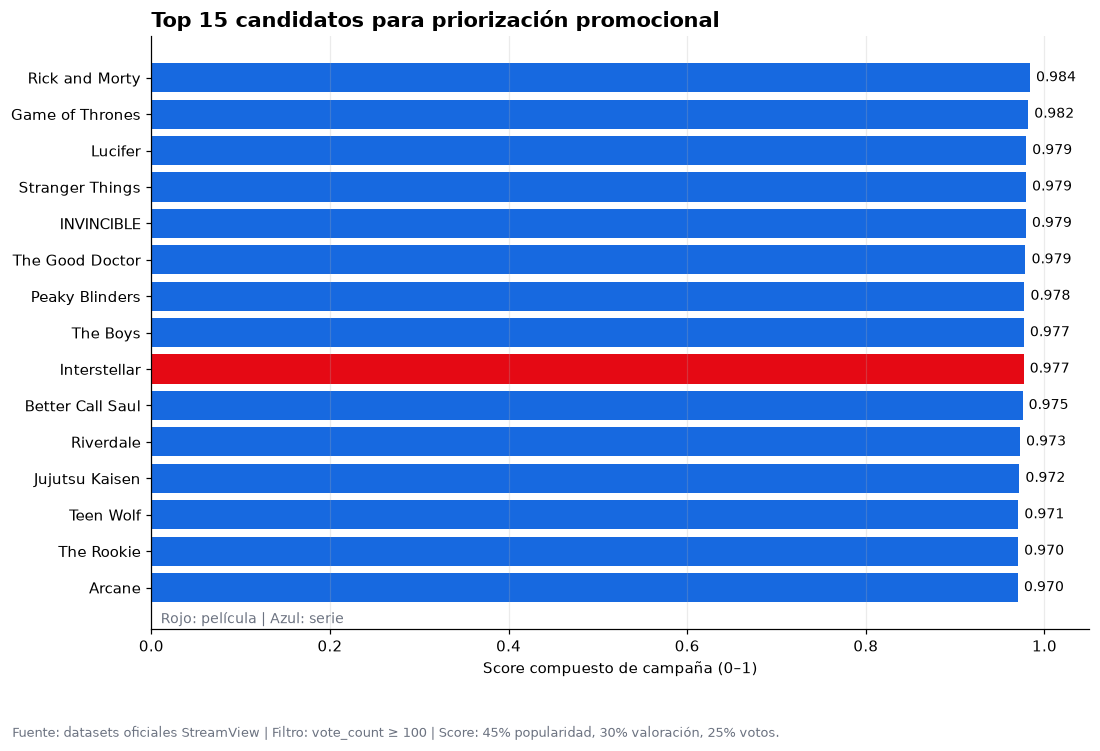

In [11]:
candidatos = base_marketing[base_marketing['vote_count'] >= 100].copy()
top_campanias = candidatos.nlargest(15, 'score_campania')[[
    'title', 'tipo_es', 'genres', 'language', 'popularity', 'vote_average', 'vote_count',
    'score_campania', 'cuadrante_campania'
]].copy()

top_campanias['titulo_etiqueta'] = top_campanias['title'].str.slice(0, 45)
plot = top_campanias.sort_values('score_campania')
colores = np.where(plot['tipo_es'] == 'Película', ROJO, AZUL)

fig, ax = plt.subplots(figsize=(11, 7))
barras = ax.barh(plot['titulo_etiqueta'], plot['score_campania'], color=colores)
ax.bar_label(barras, labels=[f'{x:.3f}' for x in plot['score_campania']], padding=4, fontsize=9)
ax.set_title('Top 15 candidatos para priorización promocional')
ax.set_xlabel('Score compuesto de campaña (0–1)')
ax.set_xlim(0, min(1.05, plot['score_campania'].max() * 1.08))
ax.grid(axis='x', alpha=.25)
ax.text(.01,.01, 'Rojo: película | Azul: serie', transform=ax.transAxes, color=GRIS, fontsize=9)
nota_fuente(fig, 'Fuente: datasets oficiales StreamView | Filtro: vote_count ≥ 100 | Score: 45% popularidad, 30% valoración, 25% votos.')
guardar(fig, '03_top_candidatos_campania')
plt.show()

top_campanias = top_campanias.drop(columns='titulo_etiqueta')

### 6.4 ¿Cómo segmentar la estrategia de campaña?

**Gráfico:** matriz de dispersión por cuadrantes.  
**Razón:** permite distinguir simultáneamente alcance potencial (popularidad) y calidad percibida (valoración). Las líneas de mediana son puntos de referencia descriptivos, no objetivos de negocio absolutos.

Figura guardada: ..\images\marketing\04_matriz_priorizacion.png


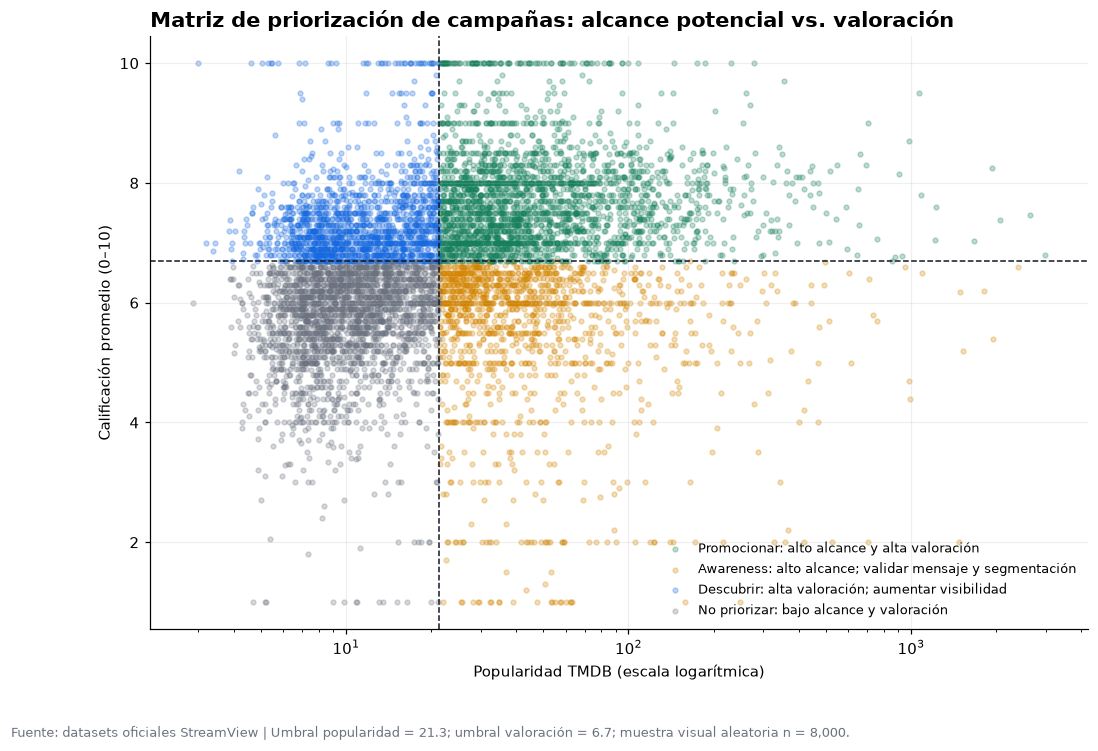

In [12]:
# Muestra aleatoria para mejorar legibilidad sin cambiar los cálculos de cuadrantes.
plot_quadrant = base_marketing.sample(min(8000, len(base_marketing)), random_state=42)
color_cuadrante = {
    'Promocionar: alto alcance y alta valoración': VERDE,
    'Awareness: alto alcance; validar mensaje y segmentación': AMBAR,
    'Descubrir: alta valoración; aumentar visibilidad': AZUL,
    'No priorizar: bajo alcance y valoración': GRIS,
}
fig, ax = plt.subplots(figsize=(11, 7))
for nombre, color in color_cuadrante.items():
    sub = plot_quadrant[plot_quadrant['cuadrante_campania'] == nombre]
    ax.scatter(sub['popularity'], sub['vote_average'], s=10, alpha=.27, color=color, label=nombre)

ax.axvline(umbral_pop, color=OSCURO, ls='--', lw=1)
ax.axhline(umbral_val, color=OSCURO, ls='--', lw=1)
ax.set_xscale('log')
ax.set_title('Matriz de priorización de campañas: alcance potencial vs. valoración')
ax.set_xlabel('Popularidad TMDB (escala logarítmica)')
ax.set_ylabel('Calificación promedio (0–10)')
ax.legend(frameon=False, fontsize=8.5, loc='lower right')
ax.grid(alpha=.2)
nota_fuente(fig, f'Fuente: datasets oficiales StreamView | Umbral popularidad = {umbral_pop:.1f}; umbral valoración = {umbral_val:.1f}; muestra visual aleatoria n = {len(plot_quadrant):,}.')
guardar(fig, '04_matriz_priorizacion')
plt.show()

### 6.5 ¿Qué idiomas y mercados sostienen oportunidades de comunicación?

**Gráfico:** dos rankings de barras horizontales.  
**Razón:** las barras ordenadas permiten comparar categorías nominales. Los países corresponden a coproducciones; por ello no se deben sumar para obtener el total de títulos.

Figura guardada: ..\images\marketing\05_idiomas_paises_marketing.png


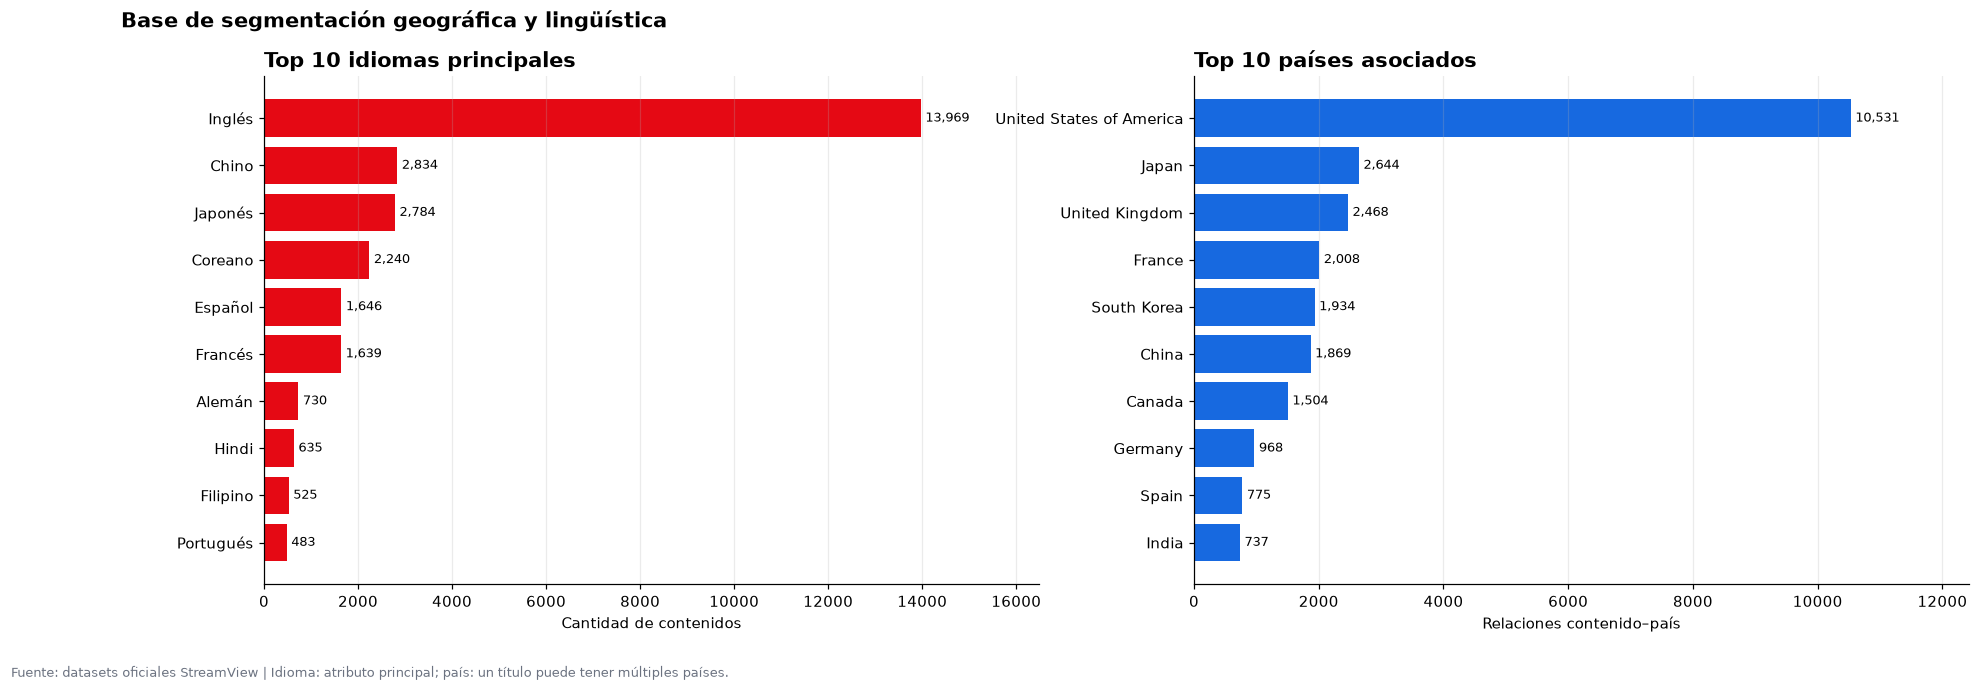

In [13]:
top_idiomas = catalogo['idioma'].value_counts().head(10).sort_values()
top_paises = por_pais['pais'].value_counts().head(10).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
for ax, serie, color, titulo, xlabel in [
    (axes[0], top_idiomas, ROJO, 'Top 10 idiomas principales', 'Cantidad de contenidos'),
    (axes[1], top_paises, AZUL, 'Top 10 países asociados', 'Relaciones contenido–país'),
]:
    barras = ax.barh(serie.index, serie.values, color=color)
    ax.bar_label(barras, fmt='{:,.0f}', padding=3, fontsize=8.5)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, serie.max()*1.18)
    ax.grid(axis='x', alpha=.25)

fig.suptitle('Base de segmentación geográfica y lingüística', x=.06, ha='left', fontweight='bold', fontsize=14)
nota_fuente(fig, 'Fuente: datasets oficiales StreamView | Idioma: atributo principal; país: un título puede tener múltiples países.')
guardar(fig, '05_idiomas_paises_marketing')
plt.show()

### 6.6 ¿Cómo evoluciona la incorporación del catálogo?

**Gráfico:** líneas por año de incorporación (`date_added`).  
**Razón:** el tiempo es una variable ordenada y las líneas permiten comparar tendencias entre películas y series. Se utiliza `year_added`, no `release_year`, porque Marketing necesita conocer cuándo los títulos ingresan a la plataforma. Además, `release_year` muestra un patrón excesivamente regular en las películas (1.000 títulos por año) que sugiere una muestra balanceada y no una tendencia de producción real.

Figura guardada: ..\images\marketing\06_incorporacion_temporal.png


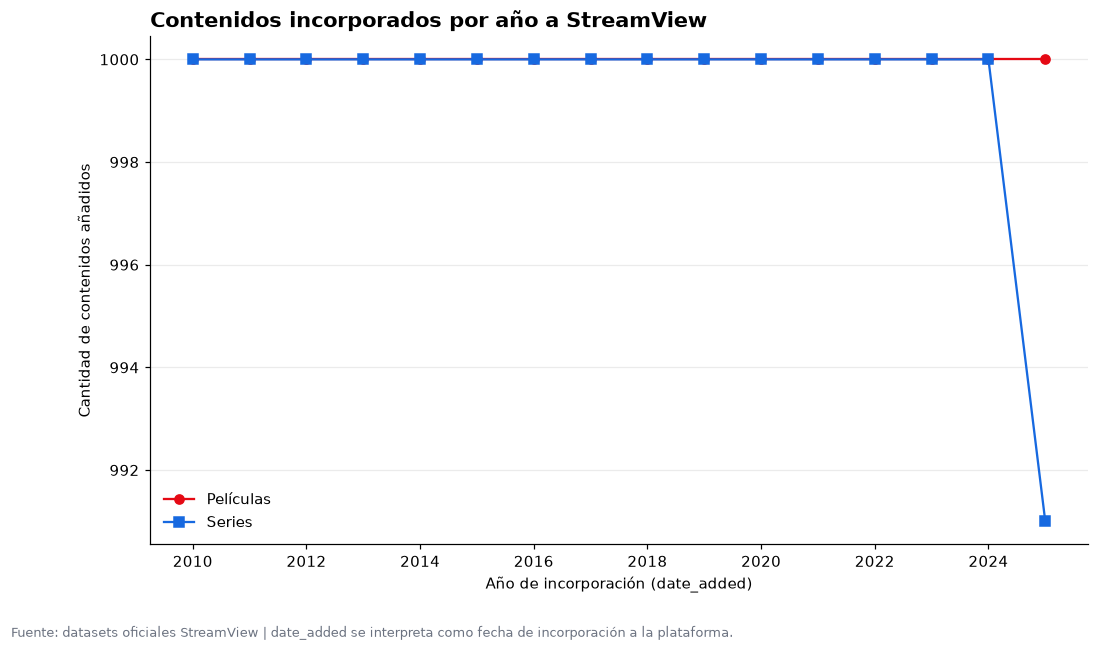

In [14]:
evolucion = (catalogo.groupby(['year_added', 'type']).size()
             .unstack(fill_value=0).sort_index())
evolucion = evolucion.rename(columns={'Movie':'Películas', 'TV Show':'Series'})

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(evolucion.index, evolucion.get('Películas', pd.Series(dtype=float)), marker='o', color=ROJO, label='Películas')
ax.plot(evolucion.index, evolucion.get('Series', pd.Series(dtype=float)), marker='s', color=AZUL, label='Series')
ax.set_title('Contenidos incorporados por año a StreamView')
ax.set_xlabel('Año de incorporación (date_added)')
ax.set_ylabel('Cantidad de contenidos añadidos')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=.25)
nota_fuente(fig, 'Fuente: datasets oficiales StreamView | date_added se interpreta como fecha de incorporación a la plataforma.')
guardar(fig, '06_incorporacion_temporal')
plt.show()

## 7. Storytelling para el informe de Marketing

### ¿Qué está ocurriendo?
El catálogo ofrece una base equilibrada de películas y series, pero está concentrado en determinados idiomas, países y familias de género. Al mismo tiempo, los títulos no tienen el mismo perfil promocional: algunos combinan alcance y valoración, mientras otros requieren estrategias de descubrimiento o validación de mensaje.

### ¿Por qué importa?
Una campaña que use únicamente popularidad podría amplificar títulos con recepción débil; una campaña que use únicamente calificación podría seleccionar títulos sin alcance. La Gerencia de Marketing necesita segmentar y priorizar con señales complementarias.

### ¿Qué evidencia lo demuestra?
Las visualizaciones de potencial por género, matriz de cuadrantes, ranking de candidatos y distribución geográfico-lingüística proporcionan la evidencia. La tabla de candidatos conserva popularidad, calificación, votos, tipo y género para revisión humana.

### ¿Qué decisiones se recomiendan?
1. Priorizar el cuadrante **Promocionar** para campañas de alto impacto.
2. Usar el cuadrante **Descubrir** para campañas de recomendación, contenido editorial y posicionamiento de “joyas ocultas”.
3. Usar **Awareness** cuando haya alcance potencial pero la valoración sea menor; validar creatividad, segmento y propuesta de valor.
4. Aplicar filtros por idioma, país, tipo y género en el dashboard antes de asignar presupuesto.
5. No afirmar éxito comercial hasta integrar datos internos de reproducciones, conversiones, costos y retención.

## 8. Justificación de diseño

| Visualización | Pregunta | Audiencia | Justificación |
|---|---|---|---|
| Barras de familias de género | ¿Qué categorías hay para promocionar? | Marketing | La longitud permite comparar rankings de categorías de forma precisa. |
| Dispersión de familias | ¿Qué familias combinan alcance y calidad? | Marketing | Relaciona dos métricas cuantitativas; el tamaño incorpora volumen. |
| Top candidatos | ¿Qué títulos priorizar? | Marketing | Un ranking ordenado facilita selección y comunicación ejecutiva. |
| Matriz de cuadrantes | ¿Qué estrategia requiere cada título? | Marketing | Dos ejes con umbrales hacen visible la acción recomendada. |
| Barras idioma/país | ¿Dónde segmentar? | Marketing | Expone concentración por atributos nominales sin sugerir causalidad. |
| Línea temporal | ¿Cuándo ingresó contenido? | Marketing | Muestra evolución de incorporaciones en una variable temporal. |

**Principios de percepción aplicados:** no se utilizan gráficos 3D; los rankings siguen orden descendente; las escalas se etiquetan; se usan colores consistentes por tipo; el color no es la única codificación; los gráficos incluyen fuente, período y alcance.

## 9. Limitaciones y siguiente paso

### Limitaciones

- No hay datos de reproducciones, tasa de clic, conversión, retención, presupuesto de campaña ni disponibilidad territorial. Por tanto, este notebook **prioriza señales de catálogo**, no mide rendimiento comercial real.
- `popularity` es un índice TMDB relativo, no consumo dentro de StreamView.
- La información de país y género es multivalor: los conteos por categoría no se suman al total del catálogo.
- La calidad de `rating` y `duration` no permite una segmentación etaria o por duración confiable.
- La evolución basada en `release_year` no se utiliza para inferir crecimiento, porque los datos de películas están balanceados artificialmente por año.

### Salidas para el informe y dashboard

- Gráficos guardados en `images/marketing/`.
- Tabla `top_campanias` para la sección de recomendaciones y para una tabla interactiva.
- Tabla `rendimiento_familias` para el gráfico y filtros de categoría.
- Tabla `evolucion` para el análisis temporal.

### Próximo paso

Construir un dashboard de Marketing con cuatro vistas: **Resumen**, **Segmentos**, **Prioridad de campañas** y **Detalle de títulos**. Sus filtros mínimos son tipo, familia de género, idioma, país, año de incorporación y mínimo de votos.

In [15]:
top_paises

pais
India                         737
Spain                         775
Germany                       968
Canada                       1504
China                        1869
South Korea                  1934
France                       2008
United Kingdom               2468
Japan                        2644
United States of America    10531
Name: count, dtype: int64

In [16]:
import os

# Exportaciones del EDA.
# - catalogo_marketing_limpio.csv es el INSUMO del ETL (src/etl_marketing.py).
# - Las demás tablas del EDA se guardan en data/processed/eda/ solo como referencia: las tablas que
#   consume el dashboard (score, género, país, top, familias, evolución) las genera el ETL, con
#   unión por (type, show_id) y el idioma legible. Así el EDA no pisa los archivos del dashboard.
EXPORT_DIR = BASE / 'data' / 'processed'
EDA_DIR = EXPORT_DIR / 'eda'
EXPORT_DIR.mkdir(parents=True, exist_ok=True); EDA_DIR.mkdir(parents=True, exist_ok=True)

catalogo.to_csv(EXPORT_DIR / 'catalogo_marketing_limpio.csv', index=False)
base_marketing.to_csv(EDA_DIR / 'catalogo_marketing_score_eda.csv', index=False)
por_genero.to_csv(EDA_DIR / 'catalogo_por_genero_eda.csv', index=False)
por_pais.to_csv(EDA_DIR / 'catalogo_por_pais_eda.csv', index=False)
top_campanias.to_csv(EDA_DIR / 'top_candidatos_campania_eda.csv', index=False)
rendimiento_familias.reset_index().to_csv(EDA_DIR / 'rendimiento_familias_eda.csv', index=False)
evolucion.reset_index().to_csv(EDA_DIR / 'evolucion_incorporacion_eda.csv', index=False)

print('Archivos exportados:')
for archivo in sorted(EXPORT_DIR.rglob('*.csv')):
    print(f' - {archivo.relative_to(EXPORT_DIR)}: {os.path.getsize(archivo)/1e6:.2f} MB')
print('\nSiguiente paso: python src/etl_marketing.py  (genera las tablas del dashboard)')


Archivos exportados:
 - catalogo_marketing_limpio.csv: 16.19 MB
 - catalogo_marketing_score.csv: 18.83 MB
 - catalogo_por_genero.csv: 42.50 MB
 - catalogo_por_pais.csv: 23.26 MB
 - eda\catalogo_marketing_score_eda.csv: 17.78 MB
 - eda\catalogo_por_genero_eda.csv: 33.54 MB
 - eda\catalogo_por_pais_eda.csv: 18.53 MB
 - eda\evolucion_incorporacion_eda.csv: 0.00 MB
 - eda\rendimiento_familias_eda.csv: 0.00 MB
 - eda\top_candidatos_campania_eda.csv: 0.00 MB
 - evolucion_incorporacion.csv: 0.00 MB
 - oportunidades_comerciales.csv: 0.61 MB
 - rendimiento_familias.csv: 0.00 MB
 - top_candidatos_campania.csv: 0.00 MB

Siguiente paso: python src/etl_marketing.py  (genera las tablas del dashboard)
